In [128]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
import statsmodels.formula.api as smf

### Gerando a população

In [129]:
# para gerar a renda, quero gerar uma distribuição lognormal com mediana de R$ 4000
# dado que Y = ln(X), e a função geradora de lognormal do numpy pede a média de Y:
# mediana = e^u, onde u é a média de Y
# logo, u = ln(mediana)
mediana_desejada = 4000
u = np.log(mediana_desejada)
desv_pad = 0.5 # desvio padrão de Y

rng = np.random.default_rng(42) # apenas para fins de reprodutibilidade
renda = rng.lognormal(mean=u, sigma=desv_pad, size=20000)

clientes = pd.DataFrame({'renda': renda})

In [130]:
# para gerar o score, a ideia é gerar um valor dentro do intervalo de 300 a 1000
# que seja correlacionado com a renda (mais um ruído)
percentil_renda = clientes['renda'].rank(pct=True)

media_ruido = 0
desv_pad_ruido = 0.25
ruido = rng.normal(loc=media_ruido, scale=desv_pad_ruido, size=20000)

score = percentil_renda + ruido

# min-max scaling para o score ficar dentro de 0 e 1
score_min = score.min()
score_max = score.max()
score_normalizado = (score - score_min) / (score_max - score_min)

# passar para o intervalo [300, 1000] 
# (300 é o piso, maior renda terá score = 1. logo 300 + 700 = 1000)
clientes['score'] = (300 + (score_normalizado * 700)).round().astype(int)

In [131]:
# para o tempo de casa, será uma distribuição uniforme simples
clientes['tempo_casa'] = rng.uniform(0, 15, 20000)

In [132]:
clientes.head()

,renda,score,tempo_casa
0,4658.310837,564,14.494382
1,2378.101090,610,6.615865
2,5821.278779,718,0.159472
3,6401.784114,694,9.829883
4,1507.988686,497,1.804954


In [133]:
ruido_y0 = np.random.normal(loc=0, scale=100, size=20000)

In [134]:
clientes['y0'] = 0.25 * clientes['renda'] + 1.5 * (clientes['score'] - 600) + (30 * clientes['tempo_casa']) + ruido_y0
clientes['y1'] = clientes['y0'] + 150 # efeito constante de 150 reais (qualquer estimador deveria identificar)

In [135]:
clientes.head()

,renda,score,tempo_casa,y0,y1
0,4658.310837,564,14.494382,1528.685872,1678.685872
1,2378.101090,610,6.615865,785.348497,935.348497
2,5821.278779,718,0.159472,1826.455726,1976.455726
3,6401.784114,694,9.829883,2090.329824,2240.329824
4,1507.988686,497,1.804954,244.068786,394.068786


### Cenários de atribuição

In [136]:
# cenário A: o tratamento será aplicado de forma aleatória
# (ex: para cada cliente, será decidido se ele receberá ou não o tratamento em um cara ou coroa)
clientes_a = clientes.copy()
clientes_a['T'] = rng.binomial(n=1, p=0.5, size=20000)

In [137]:
clientes_a.head()

,renda,score,tempo_casa,y0,y1,T
0,4658.310837,564,14.494382,1528.685872,1678.685872,0
1,2378.101090,610,6.615865,785.348497,935.348497,0
2,5821.278779,718,0.159472,1826.455726,1976.455726,0
3,6401.784114,694,9.829883,2090.329824,2240.329824,0
4,1507.988686,497,1.804954,244.068786,394.068786,1


In [138]:
# cenário B: o tratamento será decidido com base no score do cliente
clientes_b = clientes.copy()

# normalização (Z score)
media_b = clientes['score'].mean()
desvio_b = clientes['score'].std()
scores_normalizados = (clientes['score'] - media_b) / desvio_b

# função sigmoid (scores baixos receberão 0, scores altos receberão 1)
sigmoid = 1 / (1 + np.exp(-scores_normalizados))

clientes_b['T'] = (sigmoid >= 0.5).astype(int)

In [139]:
clientes_b.head()

,renda,score,tempo_casa,y0,y1,T
0,4658.310837,564,14.494382,1528.685872,1678.685872,0
1,2378.101090,610,6.615865,785.348497,935.348497,0
2,5821.278779,718,0.159472,1826.455726,1976.455726,1
3,6401.784114,694,9.829883,2090.329824,2240.329824,1
4,1507.988686,497,1.804954,244.068786,394.068786,0


### Resultado real

In [140]:
clientes_a['y'] = clientes_a['y1'] * clientes_a['T'] + (1 - clientes_a['T']) * clientes_a['y0']

In [141]:
clientes_a.head()

,renda,score,tempo_casa,y0,y1,T,y
0,4658.310837,564,14.494382,1528.685872,1678.685872,0,1528.685872
1,2378.101090,610,6.615865,785.348497,935.348497,0,785.348497
2,5821.278779,718,0.159472,1826.455726,1976.455726,0,1826.455726
3,6401.784114,694,9.829883,2090.329824,2240.329824,0,2090.329824
4,1507.988686,497,1.804954,244.068786,394.068786,1,394.068786


In [142]:
clientes_b['y'] = clientes_b['y1'] * clientes_b['T'] + clientes_b['y0'] * (1 - clientes_b['T'])

In [143]:
clientes_b.head()

,renda,score,tempo_casa,y0,y1,T,y
0,4658.310837,564,14.494382,1528.685872,1678.685872,0,1528.685872
1,2378.101090,610,6.615865,785.348497,935.348497,0,785.348497
2,5821.278779,718,0.159472,1826.455726,1976.455726,1,1976.455726
3,6401.784114,694,9.829883,2090.329824,2240.329824,1,2240.329824
4,1507.988686,497,1.804954,244.068786,394.068786,0,244.068786


### Diferença de médias

In [144]:
media_a1 = clientes_a.query('T == 1')['y'].mean()
media_a0 = clientes_a.query('T == 0')['y'].mean()

dif_medias_a = media_a1 - media_a0
dif_medias_a

np.float64(146.5665356948009)

In [145]:
media_b1 = clientes_b.query('T == 1')['y'].mean()
media_b0 = clientes_b.query('T == 0')['y'].mean()

dif_medias_b = media_b1 - media_b0
dif_medias_b

np.float64(1118.5530581124935)

### Intervalo de confiança

In [146]:
# faremos 500 reamostragens
dif_bootstraps_a = []

for i in range(500):
    amostra = clientes_a.sample(n=500, replace=True)

    media_amostra1 = amostra.query('T == 1')['y'].mean()
    media_amostra0 = amostra.query('T == 0')['y'].mean()
    dif_media = media_amostra1 - media_amostra0

    dif_bootstraps_a.append(dif_media)

dif_bootstraps_b = []

for i in range(500):
    amostra = clientes_b.sample(n=500, replace = True)

    media_amostra1 = amostra.query('T == 1')['y'].mean()
    media_amostra0 = amostra.query('T == 0')['y'].mean()
    dif_media = media_amostra1 - media_amostra0

    dif_bootstraps_b.append(dif_media)

ic_inferior_a = np.percentile(dif_bootstraps_a, 2.5)
ic_superior_a = np.percentile(dif_bootstraps_a, 97.5)
print(f'Intervalo de confiança do cenário A (95%): [{ic_inferior_a}, {ic_superior_a}]')

ic_inferior_b = np.percentile(dif_bootstraps_b, 2.5)
ic_superior_b = np.percentile(dif_bootstraps_b, 97.5)
print(f'Intervalo de confiança do cenário B (95%): [{ic_inferior_b}, {ic_superior_b}]')

Intervalo de confiança do cenário A (95%): [9.89735677869813, 281.89377967968176]
Intervalo de confiança do cenário B (95%): [1023.9303317996157, 1215.260105915359]


### Decomposição do viés

In [147]:
# E[y1|T = 1] - E[y0|T = 1] (ATT) + E[y0|T = 1] - E[y0|T = 0] (viés)
def calculo_att(df):
    e_y1_t1 = df.query('T == 1')['y1'].mean()
    e_y0_t1 = df.query('T == 1')['y0'].mean()
    att = e_y1_t1 - e_y0_t1

    return att

def calculo_vies(df):
    e_y0_t1 = df.query('T == 1')['y0'].mean()
    e_y0_t0 = df.query('T == 0')['y0'].mean()
    vies = e_y0_t1 - e_y0_t0

    return vies

In [148]:
print(f'ATT: {calculo_att(clientes_a)}, Viés: {calculo_vies(clientes_a)}')

ATT: 150.0, Viés: -3.433464305199095


In [149]:
print(f'ATT: {calculo_att(clientes_b)}, Viés: {calculo_vies(clientes_b)}')

ATT: 150.00000000000023, Viés: 968.5530581124933


Como podemos notar, excluindo o viés da equação e mantendo apenas a ATT, temos o verdadeiro efeito causal de 150 (sabemos que está correto pois adicionamos esta constante anteriormente) em ambos cenários.

É interessante perceber também a diferença entre os vieses dos dois cenários de atribuição do tratamento:
- Cenário A: atribuição aleatória, o que confere um viés muito baixo. De forma que a diferença entre as médias já demostra o efeito causal
- Cenário B: atribuição baseada em uma variável de controle (score), o que confere um viés muito mais alto que o primeiro cenário. Por isso, a diferença de médias não reflete o efeito causal

A amostra é a mesma, a única coisa que mudou foi a forma de atribuição do tratamento.

### Grafo causal

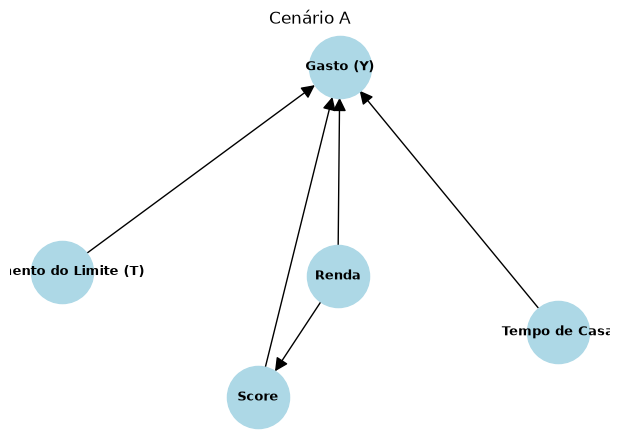

In [150]:
# cenário A
g1 = nx.DiGraph()

g1.add_edges_from(
    [
        ('Renda', 'Gasto (Y)'),
        ('Tempo de Casa', 'Gasto (Y)'),
        ('Score', 'Gasto (Y)'),
        ('Aumento do Limite (T)', 'Gasto (Y)'),
        ('Renda', 'Score')
    ]
)

plt.figure(figsize=(6, 4))

nx.draw(
    g1,
    with_labels=True,
    node_color='lightblue',
    node_size=2000,
    arrowsize=20,
    font_weight='bold',
    font_size=9
)
plt.title('Cenário A')
plt.show()

Como é possível observar pelo grafo causal do cenário A, não existe nenhum confounder pois nenhuma das variáveis influenciam o tratamento, uma vez que sua atribuição é aleatória.

De qualquer forma, é uma boa prática controlar por todas as variáveis que explicam bem Y. Portanto, uma boa regressão seria medir o impacto do Aumento do Limite (T) no Gasto (Y), controlando pela Renda, Score e Tempo de Casa.

Obs: O Score é um mediador do efeito da Renda no Gasto (Y). Se a pergunta fosse o efeito da Renda no Gasto, não seria uma boa ideia controlar pelo Score, pois ele estaria no caminho entre o tratamento e o resultado.

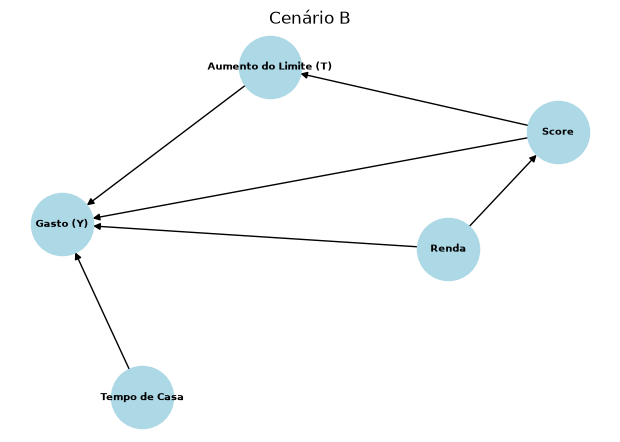

In [151]:
# cenário B
g2 = nx.DiGraph()

g2.add_edges_from(
    [
        ('Renda', 'Gasto (Y)'),
        ('Renda', 'Score'),
        ('Score', 'Aumento do Limite (T)'),
        ('Score', 'Gasto (Y)'),
        ('Tempo de Casa', 'Gasto (Y)'),
        ('Aumento do Limite (T)', 'Gasto (Y)')
    ]
)

plt.figure(figsize=(6, 4))

nx.draw(
    g2,
    with_labels=True,
    node_color='lightblue',
    node_size=2000,
    arrowsize=10,
    font_weight='bold',
    font_size=7
)
plt.title('Cenário B')
plt.show()

Note que agora no cenário B, o score passa a ser um confounder, uma vez que causa efeito tanto no Gasto (Y) quanto no Aumento do Limite (T). Esta relação também abre uma porta para influência da Renda em no Aumento do Limite (T).

A recomendação continua a mesma, medir o impacto do Aumento de Limite (T) no Gasto (Y), controlando por Renda, Score e Tempo de Casa. Porém neste caso, controlar pelo Score faz-se ainda mais necessário.

### Regressão

In [152]:
# cenário A (sem controle)
modelo_a_sem_controle = smf.ols('y ~ T', data=clientes_a).fit()
modelo_a_sem_controle.summary().tables[1]

,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,1435.2271,7.482,191.829,0.000,1420.562,1449.892
T,146.5665,10.533,13.916,0.000,125.922,167.211


In [153]:
# cenário A (controlando por renda, score e tempo de casa)
modelo_a = smf.ols('y ~ T + renda + score + tempo_casa', data=clientes_a).fit()
modelo_a.summary().tables[1]

,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,-908.0339,5.076,-178.877,0.000,-917.984,-898.084
T,150.7248,1.417,106.383,0.000,147.948,153.502
renda,0.2498,0.000,631.861,0.000,0.249,0.251
score,1.5131,0.009,166.819,0.000,1.495,1.531
tempo_casa,30.2164,0.164,184.747,0.000,29.896,30.537


In [154]:
# cenário B (sem controle)
modelo_b_sem_controle = smf.ols('y ~ T', data=clientes_b).fit()
modelo_b_sem_controle.summary().tables[1]

,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,950.3319,5.651,168.168,0.000,939.255,961.408
T,1118.5531,8.001,139.800,0.000,1102.870,1134.236


In [155]:
# cenário B (controlando por renda, score e tempo de casa)
modelo_b = smf.ols('y ~ T + renda + score + tempo_casa', data=clientes_b).fit()
modelo_b.summary().tables[1]

,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,-897.7661,6.900,-130.112,0.000,-911.291,-884.242
T,155.1343,2.453,63.255,0.000,150.327,159.941
renda,0.2498,0.000,630.543,0.000,0.249,0.251
score,1.4941,0.013,116.721,0.000,1.469,1.519
tempo_casa,30.2166,0.164,184.769,0.000,29.896,30.537


Em ambos os cenários, o modelo com controle por Renda, Score e Tempo de Casa fez um bom trabalho em medir o efeito do Aumento do Limite (T) no Gasto (Y), se aproximando bastante do efeito real conhecido de 150.

Os intervalos de [146.13, 151.67] e [143.77, 153.37] do modelo para os cenários A e B sugerem boa confiança estatística.

In [156]:
# testando em amostras menores
def amostra_menor(df):
    amostra = df.sample(n=500, replace=True)
    return amostra

amostra_a = amostra_menor(clientes_a)
amostra_b = amostra_menor(clientes_b)

def fit_modelo(df):
    modelo_ols = smf.ols('y ~ T + renda + score + tempo_casa', data=df).fit()
    return modelo_ols.summary().tables[1]

fit_modelo(amostra_a)

,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,-930.9176,30.860,-30.166,0.000,-991.550,-870.285
T,163.1094,9.056,18.011,0.000,145.316,180.902
renda,0.2484,0.003,84.911,0.000,0.243,0.254
score,1.5506,0.058,26.593,0.000,1.436,1.665
tempo_casa,29.3586,1.046,28.077,0.000,27.304,31.413


In [157]:
fit_modelo(amostra_b)

,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,-923.7417,40.757,-22.665,0.000,-1003.819,-843.665
T,137.8599,15.539,8.872,0.000,107.330,168.390
renda,0.2501,0.002,112.494,0.000,0.246,0.254
score,1.5638,0.076,20.526,0.000,1.414,1.713
tempo_casa,28.7854,1.047,27.506,0.000,26.729,30.842


Rodando o mesmo modelo em amostras menores, vemos que o modelo continua fazendo um bom trabalho em medir o efeito do Aumento do Limite (T) no Gasto (Y), mas o interessante é notar como os intervalos abriram. No cenário A, passou de [145.72, 151.23] para [122.53, 157.63], enquanto no cenário B, foi de [140.92, 150.49] para [113.34, 170.57].

Isto nos mostra a importância do tamanho da amostra para uma boa confiança estatística.

Diante disto, um pensamento tentador pode surgir: "para reduzir o viés, vou controlar por todas as variáveis possíveis".

Esta última parte será focada em mostrar que não é bem assim.

### Criação de uma nova variável: utilização (gasto/limite)

In [158]:
def cria_utilizacao(df):
    ruido_limite = rng.normal(0, 800, 20000)
    limite_base = np.clip(1.5 * df['renda'] + ruido_limite, 500, None)
    limite = limite_base * np.where(df['T'] == 1, 1.5, 1) # aumento de 50% para os tratados
    df['utilizacao'] = df['y'] / limite

cria_utilizacao(clientes_a)
cria_utilizacao(clientes_b)
clientes_a.head()

,renda,score,tempo_casa,y0,y1,T,y,utilizacao
0,4658.310837,564,14.494382,1528.685872,1678.685872,0,1528.685872,0.214476
1,2378.101090,610,6.615865,785.348497,935.348497,0,785.348497,0.205644
2,5821.278779,718,0.159472,1826.455726,1976.455726,0,1826.455726,0.195349
3,6401.784114,694,9.829883,2090.329824,2240.329824,0,2090.329824,0.191158
4,1507.988686,497,1.804954,244.068786,394.068786,1,394.068786,0.109020


In [159]:
clientes_b.head()

,renda,score,tempo_casa,y0,y1,T,y,utilizacao
0,4658.310837,564,14.494382,1528.685872,1678.685872,0,1528.685872,0.182686
1,2378.101090,610,6.615865,785.348497,935.348497,0,785.348497,0.200539
2,5821.278779,718,0.159472,1826.455726,1976.455726,1,1976.455726,0.166396
3,6401.784114,694,9.829883,2090.329824,2240.329824,1,2240.329824,0.163024
4,1507.988686,497,1.804954,244.068786,394.068786,0,244.068786,0.072139


### Novo grafo causal

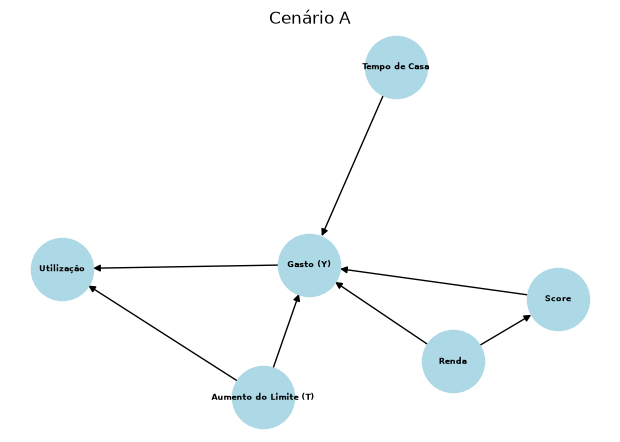

In [160]:
# cenário A
g3 = nx.DiGraph()

g3.add_edges_from(
    [
        ('Renda', 'Score'),
        ('Renda', 'Gasto (Y)'),
        ('Score', 'Gasto (Y)'),
        ('Tempo de Casa', 'Gasto (Y)'),
        ('Aumento do Limite (T)', 'Gasto (Y)'),
        ('Aumento do Limite (T)', 'Utilização'),
        ('Gasto (Y)', 'Utilização')
    ]
)

plt.figure(figsize=(6, 4))

nx.draw(
    g3,
    with_labels=True,
    node_color='lightblue',
    node_size=2000,
    arrowsize=10,
    font_weight='bold',
    font_size=6
)
plt.title('Cenário A')
plt.show()

O grafo causal nos mostra que a Utilização é uma collider, uma vez que é uma consequência do tratamento e do resultado.

Portanto, a sua inclusão no modelo é altamente proibitiva, já que esta variável cria uma associação entre tratamento e os resultados potenciais (y0 e y1) que antes não existia.

Funciona da seguinte forma, como tanto o Gasto (Y) quanto o Aumento do Limite (T) causam a Utilização, imagine que conheçamos a Utilização e o Aumento do Limite, isso nos daria informações sobre o Gasto, mas não da forma que queremos. Por exemplo, se sabemos que houve um aumento do limite (T = 1) e que a utilização é baixa, poderíamos inferir que o gasto não é tão alto, pois mesmo com o aumento do limite, a utilização é baixa. O problema é que a informação é fruto do fato da utilização ser consequência dos dois, e não de ela causar o gasto.

Desta forma, não devemos incluir a Utilização em nosso modelo. Pois criaríamos um Selection Bias.

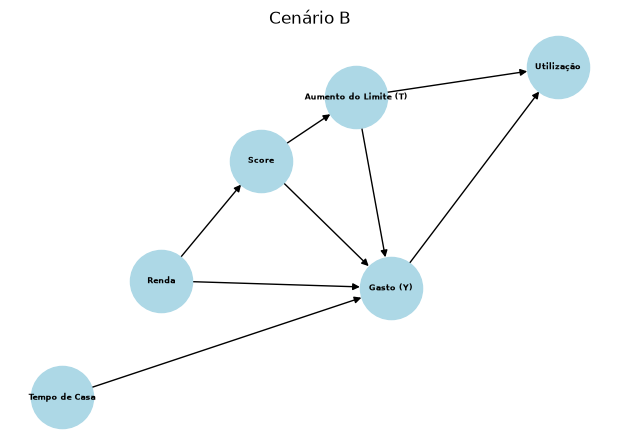

In [161]:
# cenário B
g4 = nx.DiGraph()

g4.add_edges_from(
    [
        ('Renda', 'Score'),
        ('Renda', 'Gasto (Y)'),
        ('Score', 'Gasto (Y)'),
        ('Score', 'Aumento do Limite (T)'),
        ('Tempo de Casa', 'Gasto (Y)'),
        ('Aumento do Limite (T)', 'Gasto (Y)'),
        ('Aumento do Limite (T)', 'Utilização'),
        ('Gasto (Y)', 'Utilização')
    ]
)

plt.figure(figsize=(6, 4))

nx.draw(
    g4,
    with_labels=True,
    node_color='lightblue',
    node_size=2000,
    arrowsize=10,
    font_weight='bold',
    font_size=6
)
plt.title('Cenário B')
plt.show()

O mesmo vale para o cenário B. O interessante neste caso é perceber que controlar pela confounder (Score) havia restaurado a independência entre o tratamento e os resultados alternativos (y0, y1). Ao passo que controlar pela collider (Utilização), faria com que tratamento e os resultados alternativos voltassem a ser dependentes.

### Decomposição do viés

In [162]:
# cenário A
print(f'Cenário A - ATT: {calculo_att(clientes_a)}, Viés: {calculo_vies(clientes_a)}')

Cenário A - ATT: 150.0, Viés: -3.433464305199095


In [163]:
# cenário A
print(f'Cenário B - ATT: {calculo_att(clientes_b)}, Viés: {calculo_vies(clientes_b)}')

Cenário B - ATT: 150.00000000000023, Viés: 968.5530581124933


### Regressão

In [164]:
# cenário A - sem controle
ols_sem_controle_a = smf.ols('y ~ T', data=clientes_a).fit()
ols_sem_controle_a.summary().tables[1]

,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,1435.2271,7.482,191.829,0.000,1420.562,1449.892
T,146.5665,10.533,13.916,0.000,125.922,167.211


In [165]:
# cenário A - com controle
ols_controle_a = smf.ols('y ~ T + score + renda + tempo_casa', data=clientes_a).fit()
ols_controle_a.summary().tables[1]

,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,-908.0339,5.076,-178.877,0.000,-917.984,-898.084
T,150.7248,1.417,106.383,0.000,147.948,153.502
score,1.5131,0.009,166.819,0.000,1.495,1.531
renda,0.2498,0.000,631.861,0.000,0.249,0.251
tempo_casa,30.2164,0.164,184.747,0.000,29.896,30.537


In [166]:
# cenário A - adicionando utilização
ols_controle_a = smf.ols('y ~ T + score + renda + tempo_casa + utilizacao', data=clientes_a).fit()
ols_controle_a.summary().tables[1]

,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,-968.6658,5.049,-191.857,0.000,-978.562,-958.770
T,178.2776,1.495,119.224,0.000,175.347,181.209
score,1.4235,0.009,159.742,0.000,1.406,1.441
renda,0.2550,0.000,643.707,0.000,0.254,0.256
tempo_casa,27.6318,0.167,165.196,0.000,27.304,27.960
utilizacao,522.0653,12.011,43.465,0.000,498.522,545.608


In [167]:
# cenário B - sem controle
ols_controle_b = smf.ols('y ~ T', data=clientes_b).fit()
ols_controle_b.summary().tables[1]

,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,950.3319,5.651,168.168,0.000,939.255,961.408
T,1118.5531,8.001,139.800,0.000,1102.870,1134.236


In [168]:
# cenário B - com controle
ols_controle_b = smf.ols('y ~ T + score + renda + tempo_casa', data=clientes_b).fit()
ols_controle_b.summary().tables[1]

,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,-897.7661,6.900,-130.112,0.000,-911.291,-884.242
T,155.1343,2.453,63.255,0.000,150.327,159.941
score,1.4941,0.013,116.721,0.000,1.469,1.519
renda,0.2498,0.000,630.543,0.000,0.249,0.251
tempo_casa,30.2166,0.164,184.769,0.000,29.896,30.537


In [169]:
# cenário B - adicionando utilização
ols_controle_b = smf.ols('y ~ T + score + renda + tempo_casa + utilizacao', data=clientes_b).fit()
ols_controle_b.summary().tables[1]

,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,-935.9680,6.641,-140.946,0.000,-948.984,-922.952
T,186.3132,2.444,76.237,0.000,181.523,191.103
score,1.3831,0.012,110.908,0.000,1.359,1.407
renda,0.2546,0.000,647.251,0.000,0.254,0.255
tempo_casa,27.6490,0.166,166.091,0.000,27.323,27.975
utilizacao,486.2215,10.973,44.310,0.000,464.713,507.730
